In [ ]:
import pandas as pd
import numpy as np
import sklearn
import os
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
os.chdir('/content/drive/MyDrive/Football Data Analysis/Models/xG and xT Models')

In [ ]:
data = pd.read_csv('xg_df.csv')

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16651 entries, 0 to 16650
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               16651 non-null  object 
 1   match_id         16651 non-null  int64  
 2   shot_location_x  16651 non-null  float64
 3   shot_location_y  16651 non-null  float64
 4   shot_aerial_won  16651 non-null  bool   
 5   shot_body_part   16651 non-null  object 
 6   shot_first_time  16651 non-null  bool   
 7   shot_technique   16651 non-null  object 
 8   shot_type        16651 non-null  object 
 9   shot_outcome     16651 non-null  object 
dtypes: bool(2), float64(2), int64(1), object(5)
memory usage: 1.0+ MB


In [ ]:
data.describe()

,match_id,shot_location_x,shot_location_y
count,1.665100e+04,16651.000000,16651.000000
mean,2.877706e+06,103.878230,39.640790
std,1.659241e+06,8.785119,9.836835
min,7.525000e+03,30.200000,0.700000
25%,3.036960e+05,97.850000,32.300000
50%,3.813316e+06,105.000000,39.700000
75%,3.877170e+06,111.000000,47.000000
max,3.943077e+06,120.100000,79.600000


In [ ]:
target_strings = list(data['shot_outcome'].unique())
target_strings.remove('Goal')

In [ ]:
data.replace(target_strings, 'No Goal', inplace=True)

In [ ]:
data['shot_outcome'].unique()

array(['No Goal', 'Goal'], dtype=object)

In [ ]:
predictors = data.iloc[:, 2:-1]
target = data.iloc[:, -1]

In [ ]:
predictors

,shot_location_x,shot_location_y,shot_aerial_won,shot_body_part,shot_first_time,shot_technique,shot_type
0,107.0,53.4,False,Right Foot,False,Half Volley,Open Play
1,96.5,39.9,False,Right Foot,True,Normal,Open Play
2,88.2,45.5,False,Right Foot,False,Normal,Open Play
3,98.5,49.2,False,Left Foot,False,Normal,Free Kick
4,111.2,37.8,True,Head,False,Normal,Open Play
...,...,...,...,...,...,...,...
16646,95.5,31.6,False,Left Foot,True,Normal,Open Play
16647,99.4,48.8,False,Right Foot,True,Normal,Open Play
16648,94.9,40.8,False,Right Foot,True,Half Volley,Open Play
16649,104.5,32.4,False,Right Foot,True,Half Volley,Open Play


In [ ]:
target

,shot_outcome
0,No Goal
1,No Goal
2,No Goal
3,No Goal
4,No Goal
...,...
16646,No Goal
16647,No Goal
16648,No Goal
16649,No Goal


In [ ]:
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder

target_encoder = LabelEncoder()
scaler = StandardScaler()
predictor_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

target = data.iloc[:, -1]
target = target.map({'Goal': 1,
            'No Goal': 0})

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(predictors, target, test_size=0.3, random_state=0)

In [ ]:
x_train.dtypes

,0
shot_location_x,float64
shot_location_y,float64
shot_aerial_won,bool
shot_body_part,object
shot_first_time,bool
shot_technique,object
shot_type,object


In [ ]:
str_columns = x_train.select_dtypes(['bool', 'object']).columns
str_columns

Index(['shot_aerial_won', 'shot_body_part', 'shot_first_time',
       'shot_technique', 'shot_type'],
      dtype='object')

In [ ]:
num_columns = x_train.select_dtypes(['float64']).columns
num_columns

Index(['shot_location_x', 'shot_location_y'], dtype='object')

In [ ]:
encoded_x_train = predictor_encoder.fit_transform(x_train[str_columns])
encoded_x_test = predictor_encoder.transform(x_test[str_columns])

scaled_x_train = scaler.fit_transform(x_train[num_columns])
scaled_x_test = scaler.transform(x_test[num_columns])

In [ ]:
x_train = np.hstack((scaled_x_train, encoded_x_train))
x_test = np.hstack((scaled_x_test, encoded_x_test))

In [ ]:
from imblearn.over_sampling import SMOTE

sm = SMOTE(random_state=0)

x_train_resampled, y_train_resampled = sm.fit_resample(x_train, y_train)

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(class_weight='balanced')

lr.fit(x_train_resampled, y_train_resampled)
y_pred = lr.predict(x_test)

Text(0.5, 1.0, 'xG Model Confusion Matrix')

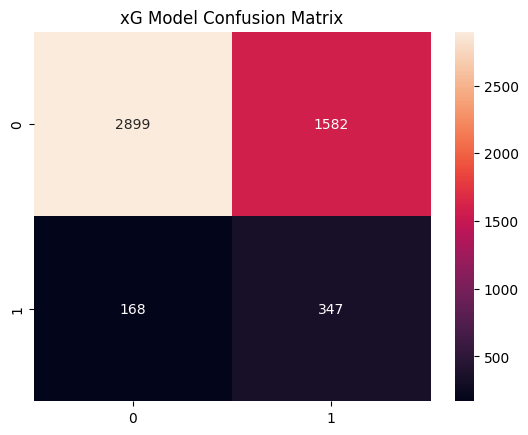

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title('xG Model Confusion Matrix')

In [ ]:
from sklearn.metrics import classification_report
cr = classification_report(y_test, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.95      0.65      0.77      4481
           1       0.18      0.67      0.28       515

    accuracy                           0.65      4996
   macro avg       0.56      0.66      0.53      4996
weighted avg       0.87      0.65      0.72      4996



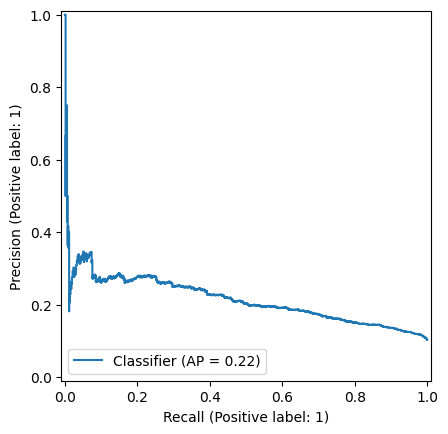

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay, precision_recall_curve

y_probs = lr.predict_proba(x_test)[:, 1]

PrecisionRecallDisplay.from_predictions(y_test, y_probs)

In [ ]:
from sklearn.metrics import log_loss

log_loss(y_test, y_probs)

0.6163752169754497

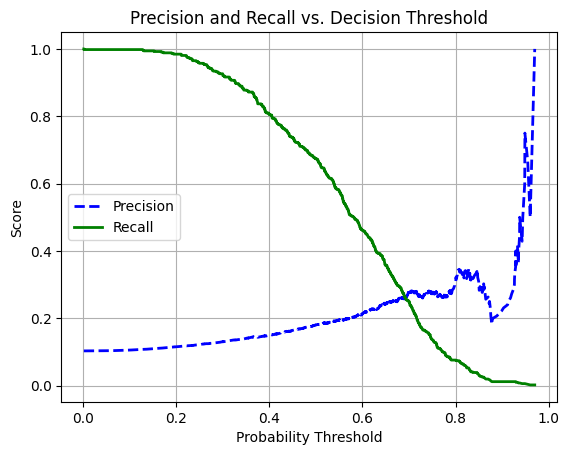

In [ ]:
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)

plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)

plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs. Decision Threshold")
plt.legend(loc="best")
plt.grid(True)
plt.show()

In [ ]:
custom_threshold = 0.69
y_pred_custom = (y_probs >= custom_threshold).astype(int)
y_pred_custom

array([1, 0, 1, ..., 1, 0, 0])

<Axes: >

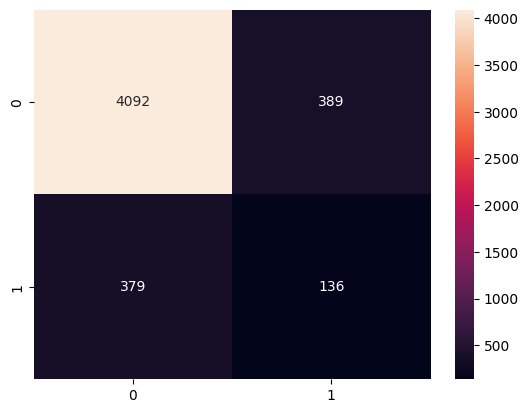

In [ ]:
custom_cm = confusion_matrix(y_test, y_pred_custom)
sns.heatmap(custom_cm, annot=True, fmt='d')


In [ ]:
cr = classification_report(y_test, y_pred_custom)
print(cr)

              precision    recall  f1-score   support

           0       0.92      0.91      0.91      4481
           1       0.26      0.26      0.26       515

    accuracy                           0.85      4996
   macro avg       0.59      0.59      0.59      4996
weighted avg       0.85      0.85      0.85      4996



In [ ]:
from xgboost import XGBClassifier

In [ ]:
ratio = np.sum(y_train == 0) / np.sum(y_train == 1)
xgb = XGBClassifier(n_estimators=300,
    max_depth=3,             # Shallow trees prevent overfitting on rare goal rows
    learning_rate=0.03,      # Slow, stable gradient steps
    subsample=0.8,           # Train on random 80% subsamples of rows
    colsample_bytree=0.8,    # Random 80% of features per tree
    random_state=42)

xgb.fit(x_train, y_train)
y_pred = xgb.predict(x_test)

Text(0.5, 1.0, 'xG Model Confusion Matrix (XGB)')

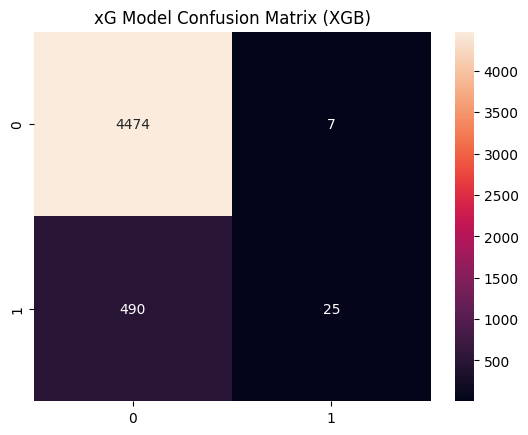

In [ ]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.title('xG Model Confusion Matrix (XGB)')

In [ ]:
cr = classification_report(y_test, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.90      1.00      0.95      4481
           1       0.78      0.05      0.09       515

    accuracy                           0.90      4996
   macro avg       0.84      0.52      0.52      4996
weighted avg       0.89      0.90      0.86      4996



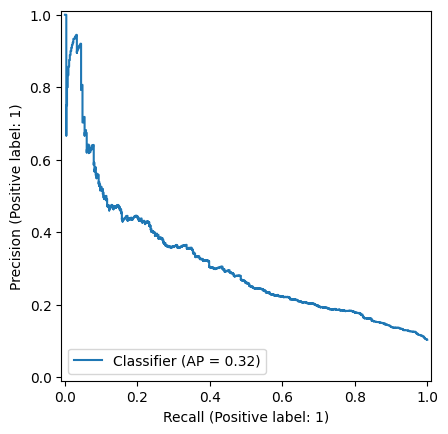

In [ ]:
y_probs = xgb.predict_proba(x_test)[:, 1]

PrecisionRecallDisplay.from_predictions(y_test, y_probs)

In [ ]:
from sklearn.metrics import log_loss

log_loss(y_test, y_probs)

0.2881670335300543

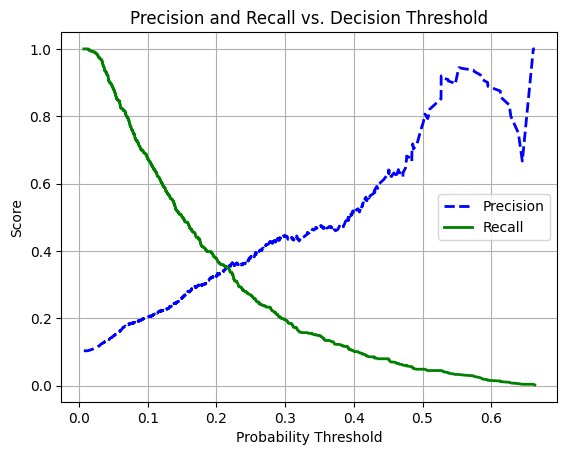

In [ ]:
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)

plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)

plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs. Decision Threshold")
plt.legend(loc="best")
plt.grid(True)
plt.show()

In [ ]:
custom_threshold = 0.25
y_pred_custom = (y_probs >= custom_threshold).astype(int)
y_pred_custom

array([1, 0, 0, ..., 1, 0, 0])

<Axes: >

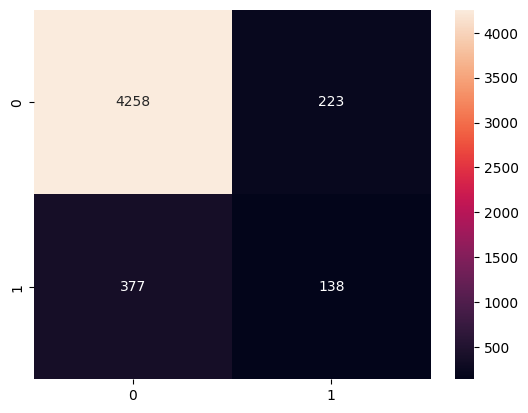

In [ ]:
custom_cm = confusion_matrix(y_test, y_pred_custom)
sns.heatmap(custom_cm, annot=True, fmt='d')

In [ ]:
cr = classification_report(y_test, y_pred_custom)
print(cr)

              precision    recall  f1-score   support

           0       0.92      0.95      0.93      4481
           1       0.38      0.27      0.32       515

    accuracy                           0.88      4996
   macro avg       0.65      0.61      0.62      4996
weighted avg       0.86      0.88      0.87      4996



In [ ]:
from sklearn.calibration import CalibratedClassifierCV
calibrated_xgb = CalibratedClassifierCV(
    estimator = xgb,
    method = 'isotonic',
    cv=5
)

calibrated_xgb.fit(x_train, y_train)
y_pred_probs = calibrated_xgb.predict_proba(x_test)[:, 1]

log_loss(y_test, y_pred_probs)

0.28856829059932515

In [ ]:
# xgb.save_model('xg_model_xgb.json')